# [12.2] Typographic Attacks and SAE Features in a Toy Two-Tower Model (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part2_clip_saes_typographic/12.2_Typographic_Attacks_and_SAE_Features_in_a_Toy_Two-Tower_Model_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part2_clip_saes_typographic/12.2_Typographic_Attacks_and_SAE_Features_in_a_Toy_Two-Tower_Model_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

An image contains a red circle, but the word **triangle** is printed underneath it. Which caption should an image–text model retrieve? The point is not that reading is bad: an image that contains only the word triangle should often retrieve “triangle”. The difficult question is whether we can reduce misleading reading without deleting legitimate reading.

By the end of this notebook, you will have shown how a sparse-feature intervention changes object-versus-word retrieval in a fully inspectable two-tower teaching organism, measured against clean images, text-only images and a wrong-feature control. You implement the feature extraction, retrieval scores, sparse autoencoder (SAE), feature search and intervention yourself.

The images are genuine rendered pixel arrays, but the encoder is deliberately transparent: colour in the top half supplies object evidence; exact template matching in the bottom half supplies a word channel; a fixed orthogonal map mixes those channels. This is **not CLIP or SigLIP**, and it does not discover their text-reading heads. It lets us audit each term before attempting that larger question. Prerequisites: [12.1] contrastive retrieval, [0.3] gradients and matrix multiplication. [6.1] is useful background for sparse autoencoders.

## Content & Learning Objectives

### 1️⃣ The picture and the word

> ##### Learning Objectives
>
> - Build image-to-caption scores from inspectable pixel features; separate object and printed-word evidence.

### 2️⃣ A sparse account of the embedding

> ##### Learning Objectives
>
> - Implement ReLU sparse coding, reconstruction, the objective and its gradient update.

### 3️⃣ Name a feature before intervening

> ##### Learning Objectives
>
> - Use image galleries and decoder directions to distinguish a feature label from a causal effect.

### 4️⃣ The price of removing text

> ##### Learning Objectives
>
> - Plot attack accuracy, clean-object accuracy and legitimate reading on the same intervention axis.

## Setup code

This study edition uses NumPy, Matplotlib and Pillow already installed in the course environment. All arrays are CPU float64, all examples are deterministic, and no model or network access occurs.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapter12_vlm_interpretability").exists())
exercises_dir = root_dir / "chapter12_vlm_interpretability" / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
from part2_clip_saes_typographic import tests as tests
from part2_clip_saes_typographic import utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=3, suppress=True)

# 1️⃣ The picture and the word

> ##### Learning Objectives
>
> - Build image-to-caption scores from inspectable pixel features; separate object and printed-word evidence.

The top and bottom halves are two information sources. An image is `(64,64,3)` in `[0,1]`. A batch has shape `(batch,height,width,channels)`. We average the top-half RGB channels to get three object signals. The bottom-half template error identifies one of three words, or the blank template. Blank means no text evidence, not a fourth object class.

The fixed palette correlates shape with colour, so our object reader cannot distinguish shape from colour. That limitation is intentional and visible: it is a good reason not to transfer a mechanistic claim from this organism to CLIP. Later, change the palette to see the failure.

### Exercise - implement `normalise_rows`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement rowwise L2 normalisation for `(batch,d)` arrays. Leave zero rows at zero using an epsilon denominator; do not add epsilon to every component. Cosine retrieval should not reward a large norm by itself.

In [2]:
def normalise_rows(x, eps=1e-12):
    return x / np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), eps)


tests.test_normalise_rows(normalise_rows)

All tests in test_normalise_rows passed!


<details>
<summary>Hint</summary>

Compute the norm along the last axis and keep that axis for broadcasting.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_normalise_rows passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `image_channels`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(batch,6)`: normalised mean RGB from the upper half, followed by a one-hot word match. `templates` contains the three word regions and optionally a final blank region. Compare mean squared pixel error in the lower half; a blank match contributes zeros to the last three columns.

In [3]:
def image_channels(images, templates):
    half = images.shape[1] // 2
    rgb = images[:, :half].mean(axis=(1, 2))
    rgb = rgb / np.maximum(rgb.sum(axis=-1, keepdims=True), 1e-12)
    errors = ((images[:, None, half:] - templates[None]) ** 2).mean(axis=(2, 3, 4))
    word_ids = errors.argmin(axis=1)
    words = np.zeros((len(images), 3))
    valid = word_ids < 3
    words[np.arange(len(images))[valid], word_ids[valid]] = 1
    return np.concatenate([rgb, words], axis=1)


tests.test_image_channels(image_channels)

All tests in test_image_channels passed!


<details>
<summary>Hint</summary>

Broadcast a template axis, reduce only spatial and RGB axes, and explicitly handle the blank template.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_image_channels passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `contrastive_logits`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute scaled cosine similarities `scale * norm(images) @ norm(captions).T`. Inputs may have unequal batch sizes. These are retrieval scores, not calibrated probabilities or the CLIP training objective.

In [4]:
def contrastive_logits(images, captions, scale=1.0):
    return scale * normalise_rows(images) @ normalise_rows(captions).T


tests.test_contrastive_logits(contrastive_logits)

All tests in test_contrastive_logits passed!


<details>
<summary>Hint</summary>

Both towers need normalisation; normalising only images changes rankings when caption norms differ.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_contrastive_logits passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

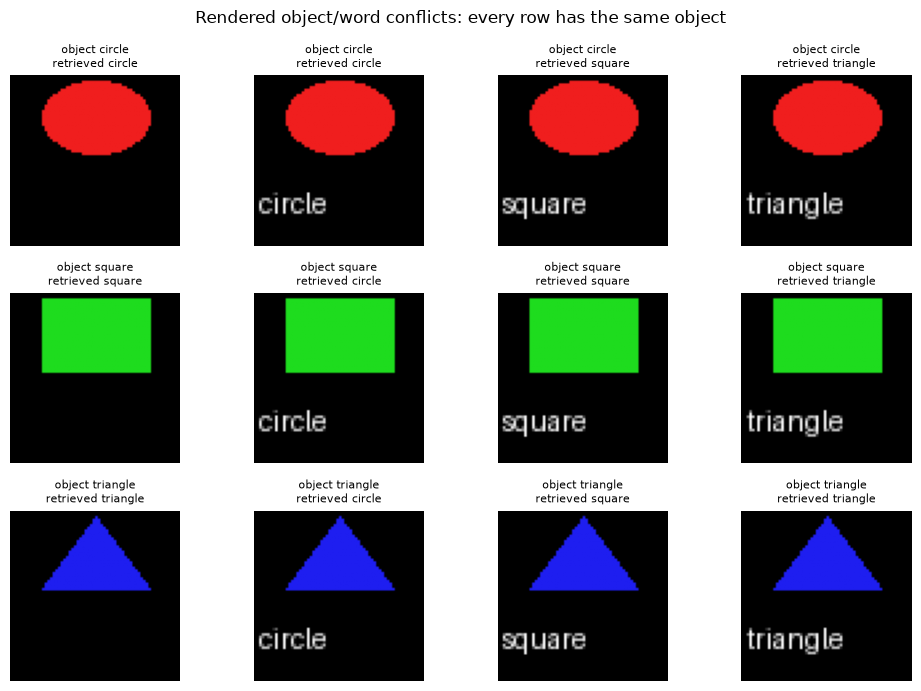

In [5]:
object_ids = np.repeat(np.arange(3), 4)
word_ids = np.tile(np.array([-1, 0, 1, 2]), 3)
images = np.stack([utils.render_card(int(o), None if w < 0 else int(w)) for o,w in zip(object_ids,word_ids)])
channels = image_channels(images, utils.word_templates())
mixing = np.linalg.qr(np.random.default_rng(7).normal(size=(6,6)))[0]
text_gain = 1.6
weighted_channels = channels * np.array([1,1,1,text_gain,text_gain,text_gain])
x = weighted_channels @ mixing
captions = np.concatenate([np.eye(3), np.eye(3)], axis=1) @ mixing
scores = contrastive_logits(x, captions)
fig, axes = plt.subplots(3,4,figsize=(10,7))
for i,ax in enumerate(axes.flat):
    ax.imshow(images[i]); ax.set_title(f"object {utils.NAMES[object_ids[i]]}\nretrieved {utils.NAMES[scores[i].argmax()]}",fontsize=8);ax.axis("off")
fig.suptitle("Rendered object/word conflicts: every row has the same object")
plt.tight_layout();plt.show()

<details><summary>Help - what is the control?</summary>

The first column has no word. Other columns keep object pixels fixed and change only the bottom label. A changed retrieval therefore follows the explicit text route in this organism. It is not evidence about a CLIP head. The gallery makes a shortcut visible rather than pretending it is an uninterpretable pretrained mechanism.

</details>

## Summary of 1️⃣

Cosine scoring is independent of global embedding norm, but the relative weights of the two evidence channels still determine the result. Normalisation does not remove a semantic conflict.

# 2️⃣ A sparse account of the embedding

> ##### Learning Objectives
>
> - Implement ReLU sparse coding, reconstruction, the objective and its gradient update.

An SAE proposes a sparse explanation of each mixed embedding $x\in\mathbb R^6$:

$$z=\operatorname{ReLU}(xW_e+b_e),\qquad\hat x=zW_d+b_d.$$

For width $m$, `W_e` is `(6,m)`, `z` is `(batch,m)`, and `W_d` is `(m,6)`. We minimise the **mean per-example squared error summed over embedding coordinates**, plus $\lambda$ times the **mean per-example sum of latent activations**. Be precise about the denominator: averaging over coordinates as well would change the effective sparsity weight.

The L1 penalty does not magically make a latent a human concept. Decoder scaling can change the penalty without changing reconstruction. This little fit is an exercise in the objective, not a claim that the chosen width/penalty identifies unique factors.

### Exercise - implement `encode_sae`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return nonnegative activations from the affine encoder. Preserve batch and latent axes.

In [6]:
def encode_sae(x, w_e, b_e):
    return np.maximum(x @ w_e + b_e, 0)


tests.test_encode_sae(encode_sae)

All tests in test_encode_sae passed!


<details>
<summary>Hint</summary>

ReLU acts after the bias, not on the weights.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_encode_sae passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `decode_sae`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Reconstruct the embedding from latent rows and decoder rows. Include the decoder bias even when all latents are zero.

In [7]:
def decode_sae(z, w_d, b_d):
    return z @ w_d + b_d


tests.test_decode_sae(decode_sae)

All tests in test_decode_sae passed!


<details>
<summary>Hint</summary>

A latent indexes a decoder row; do not transpose a nonsquare decoder.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_decode_sae passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `sparse_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the scalar objective described above. `alpha` is nonnegative; reconstruction and latent sums share the example denominator.

In [8]:
def sparse_loss(x, reconstruction, z, alpha):
    return float(np.mean(np.sum((x - reconstruction)**2, axis=1)) + alpha * np.mean(z.sum(axis=1)))


tests.test_sparse_loss(sparse_loss)

All tests in test_sparse_loss passed!


<details>
<summary>Hint</summary>

Sum each example over its features, then average over examples.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_sparse_loss passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `sae_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Take one full-batch gradient step and return NEW `(w_e,b_e,w_d,b_d)` arrays. Use the old decoder when backpropagating into the encoder. At a ReLU kink use derivative zero. The test compares every parameter with independent central finite differences.

In [9]:
def sae_step(x, w_e, b_e, w_d, b_d, alpha, lr):
    pre = x @ w_e + b_e
    z = np.maximum(pre, 0)
    residual = z @ w_d + b_d - x
    d_reconstruction = 2 * residual / len(x)
    d_pre = (d_reconstruction @ w_d.T + alpha / len(x)) * (pre > 0)
    return (w_e - lr * x.T @ d_pre,
            b_e - lr * d_pre.sum(axis=0),
            w_d - lr * z.T @ d_reconstruction,
            b_d - lr * d_reconstruction.sum(axis=0))


tests.test_sae_step(sae_step)

All tests in test_sae_step passed!


<details>
<summary>Hint</summary>

Apply the chain rule in reverse: reconstruction, decoder, ReLU, encoder. No autodiff library is needed for these four tiny arrays.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_sae_step passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `fit_sae`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Run a bounded deterministic CPU fit. Initialise the encoder with Gaussian scale 0.2, encoder bias 0.1, the decoder with its transpose, and decoder bias zero. Record the pre-update objective at each step. Return four fitted arrays and the loss list. This is a teaching fit, not hyperparameter selection.

In [10]:
def fit_sae(x, width=12, steps=400, lr=0.04, alpha=0.01, seed=0):
    rng = np.random.default_rng(seed)
    w_e = rng.normal(scale=0.2, size=(x.shape[1], width))
    b_e = np.full(width, 0.1)
    w_d = w_e.T.copy()
    b_d = np.zeros(x.shape[1])
    losses = []
    for _ in range(steps):
        z = encode_sae(x, w_e, b_e)
        losses.append(sparse_loss(x, decode_sae(z,w_d,b_d), z, alpha))
        w_e,b_e,w_d,b_d = sae_step(x,w_e,b_e,w_d,b_d,alpha,lr)
    return w_e,b_e,w_d,b_d,losses


tests.test_fit_sae(fit_sae)

All tests in test_fit_sae passed!


<details>
<summary>Hint</summary>

Keep the exact initialisation and recipe fixed; compare the final objective to the first rather than expecting a universal numeric threshold.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_fit_sae passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

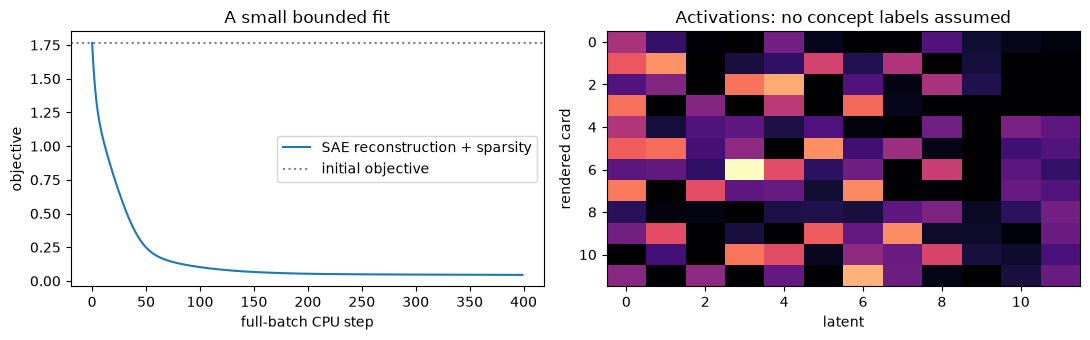

reconstruction squared error per card 0.0018


In [11]:
w_e,b_e,w_d,b_d,losses = fit_sae(x)
z = encode_sae(x,w_e,b_e)
reconstruction = decode_sae(z,w_d,b_d)
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(losses,label="SAE reconstruction + sparsity");axes[0].axhline(losses[0],ls=":",color="grey",label="initial objective");axes[0].set(xlabel="full-batch CPU step",ylabel="objective",title="A small bounded fit");axes[0].legend()
axes[1].imshow(z,aspect="auto",cmap="magma");axes[1].set(xlabel="latent",ylabel="rendered card",title="Activations: no concept labels assumed")
plt.tight_layout();plt.show()
print("reconstruction squared error per card",np.mean(np.sum((reconstruction-x)**2,axis=1)).round(4))

<details><summary>Help - low loss is not a feature interpretation</summary>

Many coordinate systems can reconstruct these twelve images. The activation heatmap tells us which cards a latent prefers, not whether it isolates text reading. The objective curve checks optimisation and its initial-objective baseline; the next gallery checks a proposed meaning. Repeatedly inspecting this fixed collection makes it monitored practice, not a held-out concept test.

</details>

## Summary of 2️⃣

You have implemented an actual tiny sparse-coding fit. Reconstruction, sparsity, activation support and downstream effects are distinct measurements.

# 3️⃣ Name a feature before intervening

> ##### Learning Objectives
>
> - Use image galleries and decoder directions to distinguish a feature label from a causal effect.

### Exercise - implement `top_examples`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the top `k` example indices for one latent, in descending activation order. Break ties by original example index using a stable sort. Never reorder image/annotation pairing.

In [12]:
def top_examples(activations, feature, k=4):
    return np.argsort(-activations[:, feature], kind="stable")[:k]


tests.test_top_examples(top_examples)

All tests in test_top_examples passed!


<details>
<summary>Hint</summary>

Stable descending sorting keeps equal activations in their original order.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_top_examples passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `feature_direction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the unit decoder direction of a selected feature. A zero decoder row stays zero. This is a direction in the mixed embedding space, not a pixel mask.

In [13]:
def feature_direction(w_d, feature):
    row = w_d[feature]
    return row / max(np.linalg.norm(row), 1e-12)


tests.test_feature_direction(feature_direction)

All tests in test_feature_direction passed!


<details>
<summary>Hint</summary>

Normalise one row, not the full decoder matrix.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_feature_direction passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `ablate_direction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Remove a fraction `strength` of each embedding’s projection onto a unit direction. Return a new array. `strength=0` is identity and `strength=1` removes that projection exactly. This projection intervention differs from zeroing an SAE latent and re-decoding.

In [14]:
def ablate_direction(x, unit_direction, strength=1.0):
    return x - strength * (x @ unit_direction)[:,None] * unit_direction[None]


tests.test_ablate_direction(ablate_direction)

All tests in test_ablate_direction passed!


<details>
<summary>Hint</summary>

The outer product of scalar projections and the direction gives the component to remove.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_ablate_direction passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

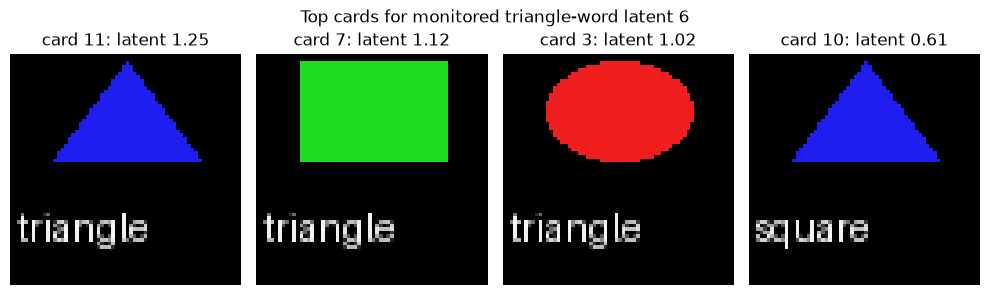

In [15]:
# Choose on the already-seen gallery; this is a labelled diagnostic, not discovery on TEST.
word_triangle = (word_ids == 2).astype(float)
centered = z - z.mean(axis=0)
correlation = centered.T @ (word_triangle-word_triangle.mean())
correlation /= np.maximum(np.linalg.norm(centered,axis=0)*np.linalg.norm(word_triangle-word_triangle.mean()),1e-12)
feature = int(correlation.argmax())
direction = feature_direction(w_d, feature)
chosen = top_examples(z,feature,4)
fig, axes = plt.subplots(1,4,figsize=(10,3))
for ax,i in zip(axes,chosen):
    ax.imshow(images[i]);ax.set_title(f"card {i}: latent {z[i,feature]:.2f}");ax.axis("off")
fig.suptitle(f"Top cards for monitored triangle-word latent {feature}")
plt.tight_layout();plt.show()

<details><summary>Help - a gallery suggests a hypothesis</summary>

We used known printed-label annotations to choose a feature. That selection is explicitly supervised and already exposed. It does not establish that the feature is exclusively a text detector; object shape and colour can remain mixed into its decoder. A clean-side-effect curve is therefore part of the intervention, not an optional footnote.

</details>

## Summary of 3️⃣

A decoder direction gives an executable intervention. A top-activation gallery supplies a fallible interpretation of that intervention.

# 4️⃣ The price of removing text

> ##### Learning Objectives
>
> - Plot attack accuracy, clean-object accuracy and legitimate reading on the same intervention axis.

### Exercise - implement `forced_choice_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return mean exact-match accuracy from rowwise argmax scores and integer targets. NumPy’s first-index argmax breaks ties. The denominator is the number of cards, not the number of captions.

In [16]:
def forced_choice_accuracy(scores, targets):
    return float(np.mean(scores.argmax(axis=1) == targets))


tests.test_forced_choice_accuracy(forced_choice_accuracy)

All tests in test_forced_choice_accuracy passed!


<details>
<summary>Hint</summary>

Make one prediction per row and compare it to that row’s target.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_forced_choice_accuracy passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `tradeoff_curve`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

For each intervention strength, ablate the direction, compute cosine retrieval and score the fixed targets. Return a NumPy array in the input strength order. All labels and example order remain fixed.

In [17]:
def tradeoff_curve(x, captions, targets, direction, strengths):
    return np.array([forced_choice_accuracy(contrastive_logits(ablate_direction(x,direction,a),captions),targets) for a in strengths])


tests.test_tradeoff_curve(tradeoff_curve)

All tests in test_tradeoff_curve passed!


<details>
<summary>Hint</summary>

Call the already-tested projection, retrieval and accuracy methods; do not change captions or select examples by whether the intervention works.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_tradeoff_curve passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

Before running the panel, predict whether removing one selected decoder direction can improve the misleading-label cases **without** hurting the text-only cases. Then predict whether the direction with smallest label correlation should work as well. You have already inspected the gallery, so this is guided practice.

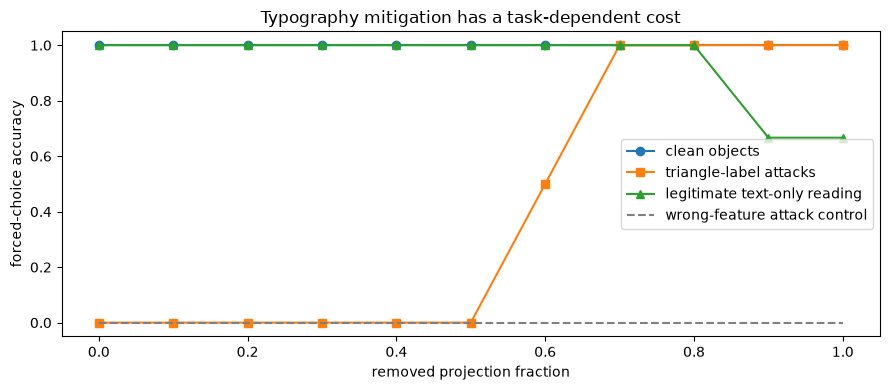

counts: clean 3 attacks 2 text-only 3


In [18]:
strengths = np.linspace(0,1,11)
clean = word_ids < 0
attack = (word_ids == 2) & (object_ids != 2)
text_images = np.stack([utils.render_card(0,j,False) for j in range(3)])
text_x = (image_channels(text_images,utils.word_templates()) * np.array([1,1,1,text_gain,text_gain,text_gain])) @ mixing
wrong_direction = feature_direction(w_d,int(np.argmin(np.abs(correlation))))
fig, ax = plt.subplots(figsize=(9,4))
for label,values,targets,style in [
    ("clean objects",x[clean],object_ids[clean],"-o"),
    ("triangle-label attacks",x[attack],object_ids[attack],"-s"),
    ("legitimate text-only reading",text_x,np.arange(3),"-^")]:
    ax.plot(strengths,tradeoff_curve(values,captions,targets,direction,strengths),style,label=label)
ax.plot(strengths,tradeoff_curve(x[attack],captions,object_ids[attack],wrong_direction,strengths),"--",color="grey",label="wrong-feature attack control")
ax.set(xlabel="removed projection fraction",ylabel="forced-choice accuracy",ylim=(-.05,1.05),title="Typography mitigation has a task-dependent cost")
ax.legend();plt.tight_layout();plt.show()
print("counts: clean",clean.sum(),"attacks",attack.sum(),"text-only",len(text_x))

## Interpreting the result

The panel is the signature result. In the fixed CPU reference fixture, clean accuracy stays 3/3, attack accuracy rises from 0/2 at strength 0 to 2/2 at strength 0.7, and text-only reading drops from 3/3 to 2/3 at strength 0.9. The wrong-feature control remains 0/2. The fitted reconstruction squared error per card is 0.0018 to four decimals; this is a monitored teaching-fit number, not independent evaluation. Its three denominators are deliberately visible. The attack subset fixes the misleading word to triangle and excludes triangle objects. The text-only subset asks a different legitimate task: identify what is written. An intervention that deletes all word information can improve one while ruining the other. The wrong-feature line checks whether any decoder direction would have sufficed; if it also improves, revise the localisation hypothesis.

Do not assume the learned feature will remove the entire word channel. The tiny SAE may distribute it over several correlated latents. If the curve stays flat, that is a result about this selected projection, not a failure of the accuracy code. Compare the known template-channel direction `mixing[5]` as an explicitly privileged oracle before making a stronger claim.

## Try it yourself

Keep the fitted SAE fixed and change only the printed-word gain from 1.6 to 0.7. Predict the retrieval changes before running. This changes the conflict strength, not the train/test label. Then redraw one object in a different colour: our declared colour reader should fail, illustrating the encoder’s boundary.

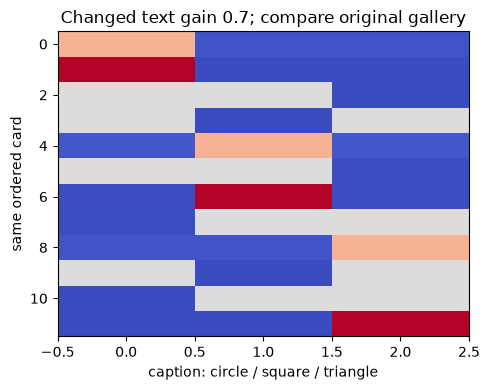

In [19]:
play_text_gain = 0.7
play_x = (channels * np.array([1,1,1,play_text_gain,play_text_gain,play_text_gain])) @ mixing
play_scores = contrastive_logits(play_x,captions)
fig,ax=plt.subplots(figsize=(5,4));ax.imshow(play_scores,aspect="auto",cmap="coolwarm");ax.set(xlabel="caption: circle / square / triangle",ylabel="same ordered card",title=f"Changed text gain {play_text_gain}; compare original gallery")
plt.tight_layout();plt.show()

## Limitations

The organism’s template reader, palette and fixed mixing are specified, not learned CLIP/SigLIP vision towers. The SAE fits twelve monitored examples and has no independent concept or causal benchmark. Projection removal is not a surgical deletion of one real neuron/head. Clean object accuracy alone would hide damage to legitimate OCR. Native CLIP/SigLIP activation collection, real SAE training, exact image preprocessing/checkpoint identity and head/feature mitigation remain pending. The intervention methods and tests are the transportable part.

# ☆ Bonus

Before changing the recipe, write one prediction about the sign and size of a control difference. After running it, explain a mismatch.

## Further reading

- [Goh et al., Multimodal Neurons (2021)](https://distill.pub/2021/multimodal-neurons/): read the typographic attack and feature-gallery examples. Their CLIP observations motivate our conflict task; our template reader is a separate teaching mechanism.
- [Radford et al., CLIP (2021)](https://arxiv.org/abs/2103.00020): compare the learned encoders and contrastive objective with our fixed two-tower scoring step.
- [Gao et al., Scaling and Evaluating Sparse Autoencoders (2024)](https://arxiv.org/abs/2406.04093): compare reconstruction/sparsity evaluation and top-k SAEs with our explicitly L1-ReLU fit. We have not implemented that paper’s large-scale training recipe.